In [1]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import os
import sys
from pathlib import Path

torch.manual_seed(42) # ensure reproducibility of results

# Configure base directory for both Google Colab and local environments
if "google.colab" in sys.modules:
    drive_path = Path("/content/drive/MyDrive/pytorch-projects/pytorch-tabular-binary-classifier")
    if not drive_path.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    if drive_path.exists():
        base = str(drive_path)
    else:
        repo_name = "pytorch-tabular-binary-classifier"
        if not Path(repo_name).exists():
            !git clone https://github.com/nfor-ojong/pytorch-tabular-binary-classifier.git
        base = repo_name
else:
    cwd = Path.cwd()
    base = str(cwd.parent if cwd.name == "notebooks" else cwd)

os.makedirs(f"{base}/artifacts", exist_ok=True)
os.makedirs(f"{base}/data/cleaned-data", exist_ok=True)
os.makedirs(f"{base}/evaluation-metrics", exist_ok=True)
os.makedirs(f"{base}/model", exist_ok=True)
os.makedirs(f"{base}/plots", exist_ok=True)

# Get current device: "cuda" or "cpu"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = torch.device("cpu") # use this for now since the neural network is a small one
print(f"Model training on {device}")

train = pd.read_csv(base + "/data/cleaned-data/train_processed.csv")
val = pd.read_csv(base + "/data/cleaned-data/val_processed.csv")

Mounted at /content/drive
Model training on cpu


In [2]:
# Split data frames into features and targets
X_train = train.drop(columns=["TenYearCHD"])
y_train = train["TenYearCHD"]

X_val = val.drop(columns="TenYearCHD")
y_val = val["TenYearCHD"]

# Convert data frames to tensors
X_train_t = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)

X_val_t = torch.tensor(X_val.to_numpy(), dtype=torch.float32)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)

# Display tensor shapes
print("X_train_t shape: ", X_train_t.shape)
print("y_train_t shape: ", y_train_t.shape)
print("X_val_t shape: ", X_val_t.shape)
print("y_val_t shape: ", y_val_t.shape)

X_train_t shape:  torch.Size([2542, 18])
y_train_t shape:  torch.Size([2542, 1])
X_val_t shape:  torch.Size([848, 18])
y_val_t shape:  torch.Size([848, 1])


In [3]:
# Combine each set into a single tensor dataset
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

# Create dataloaders each of batchsize 32
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

In [4]:
# Verify class imbalance
v_counts = y_train.value_counts()

# Compute pos_weight for binary classification with BCEWithLogitsLoss
pos_weight = torch.tensor([v_counts[0]/ v_counts[1]])[0]

# Move pos_weight to GPU if available
pos_weight = pos_weight.to(device)

In [5]:
# Build Neural Network
# We will use the BCEWithLogitsLoss function
model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 64),
    nn.LeakyReLU(0.1),      # Prevents dying ReLUs completely
    nn.Dropout(0.8),        # Gentle regularization --

    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Dropout(0.8),

    nn.Linear(32, 1)
)

# Move model to GPU if available
model = model.to(device)

# Define the loss function
# Since we do not have a Sigmoid/Softmax function at the last layer of out neural network, we use the BCEWithLogitsLoss loss function
# We also set pos_weight = (# negative classes) / (# positive classes)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Define optimizer: Adam
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2) # use L2 regularization to constrain model parameters

# Define the number of epochs
epochs = 1500

losses_train = [] # store training losses across epochs
losses_val = [] # store validation losses across epochs
epoch_values = [] # store epoch values

for epoch in range(epochs):
  epoch_loss_train = 0.0 # reset epoch loss
  model.train() # put model in training mode
  for X_batch_train, y_batch_train in train_loader:
    # Move train batch data to GPU if available
    X_batch_train = X_batch_train.to(device)
    y_batch_train = y_batch_train.to(device)

    optimizer.zero_grad() # Clear the gradients at each training iteration
    preds_train = model(X_batch_train) # make predictions using the model (feedforward process)
    loss_train = criterion(preds_train, y_batch_train) # Compute the loss function

    loss_train.backward() # compute the gradients of the loss function wrt model parameters
    optimizer.step() # update the model parameters using the computed gradients
    epoch_loss_train += loss_train.item() # combine all losses across all batches (epoch loss)

  # Put model in evaluation mode and compute losses on the validation set
  model.eval() # model in evaluation mode
  epoch_loss_val = 0.0
  with torch.no_grad(): # disable gradient calculations in this block
    for X_batch_val, y_batch_val in val_loader:
      # Move validation batch data to device
      X_batch_val = X_batch_val.to(device)
      y_batch_val = y_batch_val.to(device)

      preds_val = model(X_batch_val) # make predictions
      loss_val = criterion(preds_val, y_batch_val) # compute batch validation loss
      epoch_loss_val += loss_val.item() # aggregate validation losses over all batches in one epoch

  # Store and display epoch losses after every 5 epochs
  if (epoch+1)%5 == 0:
    avg_loss_train = epoch_loss_train / len(train_loader) # average training loss for epoch (multiple of 5)
    avg_loss_val = epoch_loss_val / len(val_loader) # average validation loss for epoch (multiple of 5)
    losses_train.append(avg_loss_train)
    losses_val.append(avg_loss_val)
    epoch_values.append(epoch + 1)
    print(f"Epoch {epoch+1} train loss: {avg_loss_train} |\t val loss: {avg_loss_val}")

Epoch 5 train loss: 1.209592491388321 |	 val loss: 1.176754355430603
Epoch 10 train loss: 1.1919033586978913 |	 val loss: 1.1717087030410767
Epoch 15 train loss: 1.1676547825336456 |	 val loss: 1.1667990854808263
Epoch 20 train loss: 1.172492614388466 |	 val loss: 1.1623282943453108
Epoch 25 train loss: 1.17347691655159 |	 val loss: 1.158134596688407
Epoch 30 train loss: 1.1645634829998017 |	 val loss: 1.1539404051644462
Epoch 35 train loss: 1.1650560021400451 |	 val loss: 1.1499488524028234
Epoch 40 train loss: 1.1610276877880097 |	 val loss: 1.145674194608416
Epoch 45 train loss: 1.157356822490692 |	 val loss: 1.141628623008728
Epoch 50 train loss: 1.1517716318368911 |	 val loss: 1.1377075569970267
Epoch 55 train loss: 1.1464604258537292 |	 val loss: 1.1331955535071236
Epoch 60 train loss: 1.145682954788208 |	 val loss: 1.1285855259214128
Epoch 65 train loss: 1.1509453773498535 |	 val loss: 1.124643019267491
Epoch 70 train loss: 1.1441377758979798 |	 val loss: 1.119794590132577
Epoch

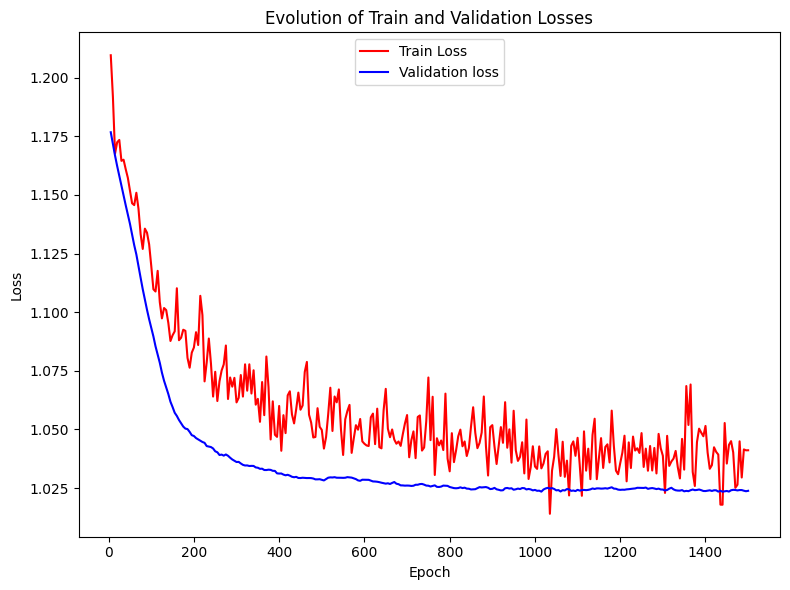

In [6]:
# Evolution of train and validation losses with number of epochs
plt.figure(figsize=(8, 6))
plt.plot(epoch_values, losses_train, color="red", label="Train Loss")
plt.plot(epoch_values, losses_val, color="blue", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Evolution of Train and Validation Losses")
plt.legend(loc="upper center")
plt.tight_layout()
plt.savefig(base + "/plots/train_validation_loss_evolution.png")
plt.show()

In [7]:
# Find the threshold that maximizes the f1-score

thresholds = torch.arange(0.1, 1.0, 0.05)
model.eval() # puts model in evaluation mode
best_threshold = 0
best_score = -float("inf")
with torch.no_grad(): # disable gradient calculations
  # Move validation data to active device
  X_val_t = X_val_t.to(device)
  y_val_t = y_val_t.to(device)
  for t in thresholds:
    preds_val = model(X_val_t) # make predictions on validation set
    probs_val = torch.sigmoid(preds_val) # compute class probabilities for validation set by applying sigmoid function
    y_preds_val = probs_val > t
    score = f1_score(y_val_t, y_preds_val)
    if score > best_score:
      best_score = score
      best_threshold = t

# Display best score (average_precision score) and best threshold
print("Best f1-score score: ", best_score)
print("Best decision threshold: ", best_threshold)

Best f1-score score:  0.3941176470588235
Best decision threshold:  tensor(0.6000)


In [8]:
# Save the model parameters and best decision threhold
torch.save(model.state_dict(), base+"/model/neural_network.pth")
Path(base + "/model/threshold.txt").write_text(str(best_threshold.item()))

18